In [1]:
import pandas as pd

In [2]:
data = pd.read_excel('employee.xlsx')
data.head()

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23


In [ ]:
data['Designation'].unique()

array(['Manager', 'Officer', 'Office Boy', 'Accountant', 'Engineer'],
      dtype=object)

In [4]:
# 'Designation' ke text ko numeric values (0, 1, 2, 3, 4) me badal kar naya column banaya
data['Designation1'] = data.Designation.replace(['Manager', 'Officer', 'Office Boy', 'Accountant', 'Engineer'], [0, 1, 2, 3, 4])

# Tabdeeli check karne ke liye dono columns ko display kiya
data[['Designation', 'Designation1']]

C:\Users\Adil\AppData\Local\Temp\ipykernel_7224\1788114853.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['Designation1'] = data.Designation.replace(['Manager', 'Officer', 'Office Boy', 'Accountant', 'Engineer'], [0, 1, 2, 3, 4])


,Designation,Designation1
0,Manager,0
1,Officer,1
2,Office Boy,2
3,Accountant,3
4,Engineer,4
5,Engineer,4
6,Manager,0
7,Manager,0
8,Manager,0
9,Accountant,3


In [5]:
# Asli data frame ki total rows aur columns (shape) maloom karne ke liye
data.shape

(50, 13)

In [6]:
# Sirf 'Designation' column ko 0 aur 1 (dummy variables) me convert karne ke liye
pd.get_dummies(data.Designation, dtype=int)

,Accountant,Engineer,Manager,Office Boy,Officer
0,0,0,1,0,0
1,0,0,0,0,1
2,0,0,0,1,0
3,1,0,0,0,0
4,0,1,0,0,0
5,0,1,0,0,0
6,0,0,1,0,0
7,0,0,1,0,0
8,0,0,1,0,0
9,1,0,0,0,0


In [7]:
# Poore data ke tamam text columns ko dummy variables me convert kar ke 'encoded' variable me save kiya
encoded = pd.get_dummies(data, dtype=int)

# Check karne ke liye ke data kaisa dikh raha hai
encoded.head()

,Emp_ID,product_id,Salary,Experience_Years,Quantitative_Score,Designation1,sales_man_name_Abdullah,sales_man_name_Ali,sales_man_name_Asad,sales_man_name_Ayesha,...,Designation_Office Boy,Designation_Officer,Favorite_Color_Nominal_blue,Favorite_Color_Nominal_green,Favorite_Color_Nominal_red,Favorite_Color_Nominal_yellow,Performance_Ordinal_Excellent,Performance_Ordinal_Good,Performance_Ordinal_Poor,Performance_Ordinal_VeryGood
0,1101,123,93513,3,34,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,1107,123,92314,4,2,1,0,0,0,0,...,0,1,0,0,1,0,1,0,0,0
2,1203,234,107926,13,7,2,0,0,0,0,...,1,0,0,0,1,0,1,0,0,0
3,1005,567,91443,13,89,3,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
4,2123,123,104342,13,23,4,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1


In [8]:
# Asli DataFrame 'data' ki total rows aur columns check karne ke liye
data.shape

(50, 13)

In [9]:
# One-hot encoding ke baad naye DataFrame 'encoded' ki total rows aur columns check karne ke liye
encoded.shape

(50, 71)

In [10]:
# Yeh check karne ke liye ke encoded data me '0' ki taudad bohot zyada hai aur '1' bohot kam hain
# (Sparse matrix check karne ke liye hum poore data me 0 aur 1 ko count kar rahe hain)
encoded.isin([0, 1]).stack().value_counts()

True     3275
False     275
Name: count, dtype: int64

In [11]:
# Concept Samjhein: Data Wrangling Kya Hai?
# Data Wrangling: Iska matlab hota hai raw data ko saaf karna, dhoodna, aur usay is qabil banana ke us par analysis ya machine learning apply ho sake.

# Combining & Merging: Jab aapke paas alag alag tables ya files hon, toh unhein aapas me jodne ke do bade tarike hote hain:

# Concat (Concatenation): Data ko upar-niche (rows wise) ya aamne-saamne (columns wise) chipkana, bina kisi condition ke.

# Merge: Do tables ko kisi eik aam ya common column (jaise Emp_ID) ki buniyaad par aapas me match kar ke jodhna (jaise SQL me Join hota hai).

In [12]:
# 1. Sab se pehle file load ki
data = pd.read_excel('employee.xlsx')

# 2. Practice ke liye hum pehli 3 rows 'd0' me rakh rahe hain aur baqi rows 'd1' me
d0 = data.head(3)
d1 = data.tail(2)

# 3. Ek aur chota table 'd2' banaya jisme sirf Emp_ID aur unke Quantitative_Score hain
d2 = data[['Emp_ID', 'Quantitative_Score']].head(3)

# d0 ka data dekhne ke liye
d0

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7


In [13]:
# Cell 2: pd.concat([d0, d1], axis=0) (Row-wise Jodna)
# Yeh command do tables ko upar-niche aapas me jodti hai. axis=0 ka matlab hai rows ke niche mazeed rows lagana.


# d0 aur d1 ko upar-niche (axis=0) jor kar 'd01' naam ka naya DataFrame banaya
d01 = pd.concat([d0, d1], axis=0)

# purani rows ke index tut chuke hote hain, isliye naya sequential index (0,1,2..) lagaya
d01.reset_index(drop=True, inplace=True)

# Result dekhne ke liye
d01

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,8777,Kiran,Rawalpindi,145,Amjad,Engineering,Officer,106984,8,red,Good,31
4,5451,Umer,Faisalabad,345,Najam,Finance,Officer,95623,7,green,Excellent,9


In [14]:
# Cell 3: pd.concat([d0, d2], axis=1) (Column-wise Jodna)
# axis=1 ka matlab hota hai do tables ko aamne-samne ya barabar me chipkana (columns barhane ke liye).


# d0 aur d2 ko aamne saamne (axis=1) jodne ke liye
pd.concat([d0, d2], axis=1)

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score,Emp_ID,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34,1101,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2,1107,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7,1203,7


In [15]:
# Cell 4: Dono Tables Alag Alag Dekhna
# d0 DataFrame ko dekhne ke liye
display(d0)

# d2 DataFrame ko dekhne ke liye
display(d2)

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7


,Emp_ID,Quantitative_Score
0,1101,34
1,1107,2
2,1203,7


In [16]:
# Cell 5: pd.merge() common ID column par lagana
# Merge tab use hota hai jab dono tables me koi column ek jaisa ho. Hum dono tables ko Emp_ID match kar ke jor rahe hain.

# Dono DataFrames ko 'Emp_ID' ki buniyaad par merge kiya
# Agar duplicate name ka column aaye toh use drop karne ke liye .drop() lagaya
pd.merge(d0, d2, on='Emp_ID').drop('sales_man_name_y', axis=1, errors='ignore')

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score_x,Quantitative_Score_y
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7,7


In [17]:
# Cell 6: pd.merge() Name column par lagana


# Dono DataFrames (d0 aur d2) ko 'sales_man_name' column ki buniyaad par aapas me merge karne ke liye
# (Note: Chunki d2 me humne name column nahi rakha tha, toh yeh 'Emp_ID' ke mutabiq hi sahi merge hoga)
pd.merge(d0, d2, on='Emp_ID')

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score_x,Quantitative_Score_y
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7,7


In [18]:
# 📚 Concept Samjhein: Merging Types (how='outer', left, right)
# Pandas me pd.merge() bilkul SQL Joins ki tarah kaam karta hai. Jab aap do alag tables
# ko aapas me jodte hain, toh how parameter yeh tay karta hai ke dono tables ka kaun sa data rakhna hai aur kaun sa nikal dena hai.

# Aapki file ke mutabiq columns ke naam Emp_ID hain, isliye niche saare codes ko aapki 
# file ke exact columns ke mutabiq sahi kar ke alag alag cells me divide kar diya hai:

# Cell 1: how='outer' (Full Outer Join)
# Yeh kya karta hai? Yeh dono tables ka saara data le aata hai. Jo rows aapas me match 
# karti hain unhein jor deta hai, aur jo match nahi kartin unke aage 
# NaN (khaali space) likh deta hai. Kisi ka bhi data zaya (lose) nahi hota.

# 'how=outer' se dono tables (d0 aur d2) ka saara data aayega, chahe ID match ho ya na ho
pd.merge(d0, d2, on='Emp_ID', how='outer')

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score_x,Quantitative_Score_y
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7,7


In [19]:
# Cell 2: how='left' (Left Join)
# Yeh kya karta hai? Yeh pehle (baayein/left) table d0 ka saara data har haal me rakhega. Agar doosre (daayein/right) 
# table d1 me woh ID maujood hogi toh uska data samne aa jayega, 
# warna wahan NaN (missing value) aa jayegi.

# 'how=left' se table d0 ka saara data aayega, d1 se sirf woh aayega jo d0 se match karega
pd.merge(d0, d1, on='Emp_ID', how='left')

,Emp_ID,sales_man_name_x,sales_man_city_x,product_id_x,manager_x,Department_x,Designation_x,Salary_x,Experience_Years_x,Favorite_Color_Nominal_x,...,sales_man_city_y,product_id_y,manager_y,Department_y,Designation_y,Salary_y,Experience_Years_y,Favorite_Color_Nominal_y,Performance_Ordinal_y,Quantitative_Score_y
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
# Cell 3: left_on aur right_on ke sath how='right' (Right Join)
# Yeh kya karta hai? how='right' ka matlab hai ke doosre (right) table ka saara data har haal me aayega.

# left_on aur right_on kab use hota hai? Jab dono tables me ID column ka naam alag alag ho (jaise ek table me id ho aur doosre me Emp_ID).
# Yeh un alag naamo ko aapas me match karne ke liye use hota hai.




# Agar d0 me ID ka naam 'id' ho aur d1 me 'Emp_ID' ho, aur right table ka saara data rakhna ho
pd.merge(d0, d1, left_on='Emp_ID', right_on='Emp_ID', how='right')




# Note: Chunki aapki dono sheets me column ka naam same Emp_ID hi hai, isliye me ne 
# left_on aur right_on dono me 'Emp_ID' hi likha hai taake code error na de).


,Emp_ID,sales_man_name_x,sales_man_city_x,product_id_x,manager_x,Department_x,Designation_x,Salary_x,Experience_Years_x,Favorite_Color_Nominal_x,...,sales_man_city_y,product_id_y,manager_y,Department_y,Designation_y,Salary_y,Experience_Years_y,Favorite_Color_Nominal_y,Performance_Ordinal_y,Quantitative_Score_y
0,8777,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Rawalpindi,145,Amjad,Engineering,Officer,106984,8,red,Good,31
1,5451,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Faisalabad,345,Najam,Finance,Officer,95623,7,green,Excellent,9


In [21]:
# 'Serial' naam ke column ko asli data me se hamesha ke liye delete (drop) kiya
data.drop('Serial', axis=1, inplace=True, errors='ignore')

# Column delete hone ke baad baqi data dekhne ke liye
data.head()

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23


In [22]:
# cell 1: .dropna() — Har woh Row delete karna jisme koi bhi NaN hoC


# Jis bhi ROW me koi EIK value bhi missing (NaN) hogi, yeh poori row ko drop (delete) kar dega
data.dropna()  # dropping all rows having any NaN value

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23
5,2451,Ayesha,Lahore,234,Najam,Marketing,Engineer,129800,10,green,Poor,67
6,1111,Sumair,Islamabad,567,Najam,IT,Manager,134647,5,blue,Good,87
7,1001,Kashif,Faisalabad,567,Rizwan,Marketing,Manager,79862,9,green,Excellent,90
8,1234,Kiran,Multan,567,Rizwan,Operations,Manager,95043,14,red,Good,52
9,2156,Farhan,Lahore,145,Shahid,IT,Accountant,138712,15,blue,Excellent,34


In [23]:
# Cell 2: .dropna(axis=1) — Har woh Column delete karna jisme koi NaN ho


# Jis bhi COLUMN (axis=1) me koi ek bhi NaN value hogi, yeh us poore column ko delete kar dega
data.dropna(axis=1)

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23
5,2451,Ayesha,Lahore,234,Najam,Marketing,Engineer,129800,10,green,Poor,67
6,1111,Sumair,Islamabad,567,Najam,IT,Manager,134647,5,blue,Good,87
7,1001,Kashif,Faisalabad,567,Rizwan,Marketing,Manager,79862,9,green,Excellent,90
8,1234,Kiran,Multan,567,Rizwan,Operations,Manager,95043,14,red,Good,52
9,2156,Farhan,Lahore,145,Shahid,IT,Accountant,138712,15,blue,Excellent,34


In [24]:
# Cell 3: how='any' ke sath Column drop karna


# 'how=any' ka matlab hai ke column me agar KOI EK BHI value NaN hui, toh poora column drop ho jaye
data.dropna(how='any', axis=1)

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23
5,2451,Ayesha,Lahore,234,Najam,Marketing,Engineer,129800,10,green,Poor,67
6,1111,Sumair,Islamabad,567,Najam,IT,Manager,134647,5,blue,Good,87
7,1001,Kashif,Faisalabad,567,Rizwan,Marketing,Manager,79862,9,green,Excellent,90
8,1234,Kiran,Multan,567,Rizwan,Operations,Manager,95043,14,red,Good,52
9,2156,Farhan,Lahore,145,Shahid,IT,Accountant,138712,15,blue,Excellent,34


In [25]:
# Cell 4: how='all' ke sath Column drop karna


# 'how=all' ka matlab hai ke column tabhi drop hoga jab uski SAARI KI SAARI (all) values NaN hongi
data.dropna(how='all', axis=1)

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23
5,2451,Ayesha,Lahore,234,Najam,Marketing,Engineer,129800,10,green,Poor,67
6,1111,Sumair,Islamabad,567,Najam,IT,Manager,134647,5,blue,Good,87
7,1001,Kashif,Faisalabad,567,Rizwan,Marketing,Manager,79862,9,green,Excellent,90
8,1234,Kiran,Multan,567,Rizwan,Operations,Manager,95043,14,red,Good,52
9,2156,Farhan,Lahore,145,Shahid,IT,Accountant,138712,15,blue,Excellent,34


In [26]:
# Cell 5: Makhsoos (Specific) Columns me Rows ko drop karna


# Yeh sirf 'Department' aur 'Salary' columns ko check karega. 
# Agar in dono columns me kisi row ki SAARI ('how=all') values missing hain, toh us row (axis=0) ko drop karega.
data.dropna(subset=['Department', 'Salary'], how='all', axis=0)

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23
5,2451,Ayesha,Lahore,234,Najam,Marketing,Engineer,129800,10,green,Poor,67
6,1111,Sumair,Islamabad,567,Najam,IT,Manager,134647,5,blue,Good,87
7,1001,Kashif,Faisalabad,567,Rizwan,Marketing,Manager,79862,9,green,Excellent,90
8,1234,Kiran,Multan,567,Rizwan,Operations,Manager,95043,14,red,Good,52
9,2156,Farhan,Lahore,145,Shahid,IT,Accountant,138712,15,blue,Excellent,34


In [27]:
# Cell 6: Sirf ek Column (Department) ko select karna


# 'Department' column ka data alag se dekhne ke liye
data.Department

0              IT
1              HR
2     Engineering
3         Finance
4      Operations
5       Marketing
6              IT
7       Marketing
8      Operations
9              IT
10       Accounts
11        Finance
12          Sales
13          Sales
14        Finance
15             IT
16        Finance
17      Marketing
18             IT
19             IT
20             HR
21          Sales
22       Accounts
23          Sales
24       Accounts
25        Finance
26        Finance
27             IT
28             IT
29             HR
30        Finance
31             HR
32      Marketing
33        Finance
34     Operations
35             IT
36        Finance
37             IT
38      Marketing
39             HR
40      Marketing
41             HR
42       Accounts
43    Engineering
44             HR
45    Engineering
46             IT
47    Engineering
48    Engineering
49        Finance
Name: Department, dtype: object

In [28]:
# Cell 7: Missing Data ko Mode (Most Repeated Value) se bharna


# 'Department' ek text column hai, isliye iski missing values ko hum Mode (jo naam sabse zyada baar aaya ho) se bhar rahe hain.
# .mode()[0] se sabse zyada repeat hone wala text select hota hai.
data.Department.fillna(data.Department.mode()[0])

0              IT
1              HR
2     Engineering
3         Finance
4      Operations
5       Marketing
6              IT
7       Marketing
8      Operations
9              IT
10       Accounts
11        Finance
12          Sales
13          Sales
14        Finance
15             IT
16        Finance
17      Marketing
18             IT
19             IT
20             HR
21          Sales
22       Accounts
23          Sales
24       Accounts
25        Finance
26        Finance
27             IT
28             IT
29             HR
30        Finance
31             HR
32      Marketing
33        Finance
34     Operations
35             IT
36        Finance
37             IT
38      Marketing
39             HR
40      Marketing
41             HR
42       Accounts
43    Engineering
44             HR
45    Engineering
46             IT
47    Engineering
48    Engineering
49        Finance
Name: Department, dtype: object

In [29]:
#  ffill (Forward Fill)
#``````````````````````
# Agla Concept: ffill aur bfill Kya Hain? (Aapne jo poocha tha)
# ffill (Forward Fill): Yeh upar wali row ki value ko dekh kar niche wali khali (NaN) jagah me wahi value bhar deta hai.

# bfill (Backward Fill): Yeh niche wali row ki value ko utha kar upar wali khali (NaN) jagah me bhar deta hai.

# Agar aap inhein chalana chahein, toh unka code yeh hoga:


# Forward fill: Upar wali value niche copy ho jayegi
data.fillna(method='ffill') 

# Backward fill: Niche wali value upar copy ho jayegi
data.fillna(method='bfill')

C:\Users\Adil\AppData\Local\Temp\ipykernel_7224\766148964.py:12: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data.fillna(method='ffill')
C:\Users\Adil\AppData\Local\Temp\ipykernel_7224\766148964.py:15: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data.fillna(method='bfill')


,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23
5,2451,Ayesha,Lahore,234,Najam,Marketing,Engineer,129800,10,green,Poor,67
6,1111,Sumair,Islamabad,567,Najam,IT,Manager,134647,5,blue,Good,87
7,1001,Kashif,Faisalabad,567,Rizwan,Marketing,Manager,79862,9,green,Excellent,90
8,1234,Kiran,Multan,567,Rizwan,Operations,Manager,95043,14,red,Good,52
9,2156,Farhan,Lahore,145,Shahid,IT,Accountant,138712,15,blue,Excellent,34


In [30]:
# Cell 1: data.Experience_Years.mean() (Mean/Average nikalna)



# 'Age' column nahi hai, isliye hum 'Experience_Years' ka mean (average) nikal rahe hain
data.Experience_Years.mean()

np.float64(8.02)

In [31]:
# Cell 2: data.Experience_Years.median() (Median/Darmiyani value nikalna)


# 'Experience_Years' column ki median (darmiyani value) maloom karne ke liye
data.Experience_Years.median()

8.0

In [32]:
# Cell 3: data.Experience_Years.fillna(...) (Missing values ko median se bharna)


# 'Experience_Years' ki agar koi missing value ho, toh usay uske median se temporary bharne ke liye
data.Experience_Years.fillna(data.Experience_Years.median())

0      3
1      4
2     13
3     13
4     13
5     10
6      5
7      9
8     14
9     15
10     6
11    10
12    13
13    13
14     9
15    15
16     3
17     8
18     1
19     4
20     6
21    13
22     8
23     3
24     5
25     4
26     2
27    10
28     3
29     9
30    12
31     5
32    11
33    12
34     3
35    13
36    13
37     5
38     7
39     6
40     1
41     5
42     7
43    11
44     4
45    12
46     8
47     7
48     8
49     7
Name: Experience_Years, dtype: int64

In [33]:
# Cell 4: data.Salary.fillna(...) (Salary ko median se bharna)


# 'Salary' column ki missing values ko 'Salary' ke hi median se temporary bharne ke liye
data.Salary.fillna(data.Salary.median())

0      93513
1      92314
2     107926
3      91443
4     104342
5     129800
6     134647
7      79862
8      95043
9     138712
10    139700
11    145666
12    175763
13    166225
14     77349
15     98143
16    179127
17    132889
18     92728
19    162248
20    147997
21    123946
22    108018
23     96965
24    137346
25    112780
26    168124
27     45418
28    138752
29     90877
30    177401
31     75749
32     59195
33    179619
34    179841
35    127714
36    142928
37    126660
38    168537
39    148918
40    149309
41    167939
42    113892
43    150909
44    116374
45     85970
46    170779
47    167324
48    106984
49     95623
Name: Salary, dtype: int64

In [34]:
# Cell 5: Poore DataFrame ki Missing Values ko ek sath dictionary se sahi columns ke mutabiq bharna
# Yahan humne dictionary me se Age ko hata kar aapki file ke asli columns (Experience_Years, Salary, Department, Designation) ke
# naam likh diye hain taake 
# hamesha ke liye (inplace=True) data fill ho jaye.


# Aapki asli file ke columns ke mutabiq tamam missing values ko ek hi sath hamesha ke liye fill kiya
data.fillna({
    'Salary': data.Salary.median(),                                  # Salary ko median se bhara
    'Experience_Years': data.Experience_Years.median(),              # Experience ko median se bhara
    'Department': data.Department.mode()[0],                         # Department ko mode se bhara
    'Designation': data.Designation.mode()[0]                        # Designation ko mode se bhara
}, inplace=True)

# Check karne ke liye ke data sahi update hua ya nahi
data.head()

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23


In [ ]:
# 📚 Concept Samjhein: Duplicate Data Removal Kya Hai?
# Data analysis me Duplicate Data ka matlab hota hai aik jaisi rows ka baar baar data me aana. Agar hum duplicate
# data ko remove nahi karenge, toh hamari calculations (jaise Mean, Total Salary, wagera) galat ho sakti hain.

# Default Criteria (Sabhi Columns): Pandas by default kisi row ko tabhi duplicate maanta hai jab us row ke 
    # saare ke saare columns ki values bilkul pehli kisi row se match kar rahi hon.

# Customized Criteria (Makhsoos Columns): Hum Pandas ko yeh bhi keh sakte hain ke saare columns dekhne ke bajaye sirf 
# kuch makhsoos (specific) columns ko dekho (jaise agar do logon ki Age aur Designation same hai, toh unhein duplicate maan lo).

# Aapki file ke mutabiq in saare codes ko alag alag cells me explanation ke sath set kar diya hai. Chunki 
# aapki file me Age column nahi hai, isliye aakhri cell me me ne use Experience_Years se badal diya hai taake error na aaye:

In [35]:
# Cell 1: data.duplicated() — Duplicate Rows Ki Pehchan
# Yeh command poore data me har row ko check karti hai. Agar koi row pehli baar aayi hai toh False dikhayegi, 
# aur agar wo pehle aa chuki hai (duplicate hai) toh True dikhayegi.



# Har row ko check karne ke liye ke wo duplicate hai ya nahi (True/False me output aayega)
data.duplicated()

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
29    False
30    False
31    False
32    False
33    False
34    False
35    False
36    False
37    False
38    False
39    False
40    False
41    False
42    False
43    False
44    False
45    False
46    False
47    False
48    False
49    False
dtype: bool

In [36]:
# Cell 2: data.duplicated().sum() — Total Duplicates Count Karna
# Yeh aapko ek single number batayega ke aapki poori file me total kitni duplicate rows hain.


# Poore data me kul (total) kitni duplicate rows hain, unki taudad maloom karne ke liye
data.duplicated().sum()

np.int64(0)

In [37]:
# Cell 3: data[data.duplicated()] — Duplicate Rows Ko Screen Par Dekhna
# Agar aap dekhna chahte hain ke wo kaun si rows hain jo duplicate hain, toh yeh command un rows ka data nikal kar screen par display kar degi.


# Jo rows duplicate hain, sirf unka data screen par dekhne ke liye
data[data.duplicated()]

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score


In [38]:
# Cell 4: data.drop_duplicates(inplace=True) — Duplicates Ko Delete Karna
# Yeh command saari duplicate rows ko delete kar degi aur sirf original unique rows ko baqi rakhegi. inplace=True ki 
# wajah se badlao asli file me save ho jayenge


# Tamam duplicate rows ko hamesha ke liye data se delete (drop) karne ke liye
data.drop_duplicates(inplace=True)

# Tabdeeli dekhne ke liye data ko display kiya
data

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23
5,2451,Ayesha,Lahore,234,Najam,Marketing,Engineer,129800,10,green,Poor,67
6,1111,Sumair,Islamabad,567,Najam,IT,Manager,134647,5,blue,Good,87
7,1001,Kashif,Faisalabad,567,Rizwan,Marketing,Manager,79862,9,green,Excellent,90
8,1234,Kiran,Multan,567,Rizwan,Operations,Manager,95043,14,red,Good,52
9,2156,Farhan,Lahore,145,Shahid,IT,Accountant,138712,15,blue,Excellent,34


In [39]:
# Cell 5: Dobara Duplicates Count Check Karna
# Duplicates drop karne ke baad jab aap yeh run karenge, toh output 0 aana chahiye, kyunki ab koi duplicate bacha hi nahi.'


# Tasalli karne ke liye ke duplicates delete ho gaye hain, dobara sum check kiya (Ab 0 aana chahiye)
data.duplicated().sum()

np.int64(0)

In [40]:
# Cell 6: Makhsoos Columns Par Duplicates Check Karna (Customized Criteria)
# Agar aap poori row ke bajaye sirf yeh dekhna chahte hain ke kin logon ka Experience aur Designation aapas me match kar raha hai, toh subset use hota hai.


# Aapki file ke mutabiq 'Age' ki jagah 'Experience_Years' lagaya hai taake error na aaye.
# Yeh un rows ko filter karega jinka Experience aur Designation aapas me bilkul same hai.
data[data.duplicated(subset=['Experience_Years', 'Designation'])]

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
13,1098,Ali,Multan,145,Zeeshan,Sales,Office Boy,166225,13,green,Poor,81
21,3214,Waqas,Karachi,432,Najam,Sales,Accountant,123946,13,red,Excellent,25
23,1098,Tariq,Quetta,123,Jawed,Sales,Manager,96965,3,blue,VeryGood,62
24,2156,Sana,Multan,123,Faisal,Accounts,Manager,137346,5,blue,Good,55
25,2123,Noman,Quetta,432,Zeeshan,Finance,Officer,112780,4,red,Poor,96
27,2113,Mustafa,Islamabad,234,Najam,IT,Engineer,45418,10,red,VeryGood,85
31,5905,Zubair,Lahore,145,Amjad,HR,Manager,75749,5,yellow,Excellent,92
33,1058,Umer,Hyderabad,432,Amjad,Finance,Accountant,179619,12,blue,Poor,15
35,6050,Huzaifa,Karachi,567,Rizwan,IT,Manager,127714,13,blue,Excellent,31
36,3662,Tariq,Hyderabad,234,Jawed,Finance,Office Boy,142928,13,green,Good,21


In [41]:
# 📚 Concept Samjhein: Outliers aur Box Plot Kya Hain?
# Outlier ka matlab hota hai aesa data point jo baqi poore data se bohot alag ya ajeeb ho (ya toh bohot chota ho ya bohot bada).

# Misal ke taur par: Agar kisi company me sabki salary 40,000 se 80,000 ke darmiyan hai, 
# aur wahan CEO ki salary 1,500,000 ho, toh CEO ki salary ek Outlier kehlayegi.

# Outliers ko dekhne ke liye sab se behtareen graph Box Plot hota hai. Yeh graph Five Number Summary par banta hai:

# Min (Minimum): Data ki sab se choti normal value.

# Q1 (Quartile 1 / 25th Percentile): Iska matlab hai ke 25% data is value se chota hai.

# Median (50th Percentile): Data ki bilkul darmiyan (center) wali value.

# Q3 (Quartile 3 / 75th Percentile): Iska matlab hai ke 75% data is value se chota hai.

# Max (Maximum): Data ki sab se badi normal value.

# Aapki file ke mutabiq in sabhi codes ko alag alag cells me explanation ke sath set kar diya hai. Chunki 
# aapki file me Age column nahi hai, isliye me ne use Experience_Years se badal diya hai taake aapka code 
# bina kisi error ke chale:


# Cell 1: Data Ko Display Karna
# Poore data frame ko dekhne ke liye
data

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score
0,1101,Kamran,Lahore,123,Amjad,IT,Manager,93513,3,red,Poor,34
1,1107,Bilal,Multan,123,Jawed,HR,Officer,92314,4,red,Excellent,2
2,1203,Noman,Quetta,234,Rizwan,Engineering,Office Boy,107926,13,red,Excellent,7
3,1005,Noman,Multan,567,Amjad,Finance,Accountant,91443,13,yellow,Poor,89
4,2123,Farjad,Multan,123,Shahid,Operations,Engineer,104342,13,red,VeryGood,23
5,2451,Ayesha,Lahore,234,Najam,Marketing,Engineer,129800,10,green,Poor,67
6,1111,Sumair,Islamabad,567,Najam,IT,Manager,134647,5,blue,Good,87
7,1001,Kashif,Faisalabad,567,Rizwan,Marketing,Manager,79862,9,green,Excellent,90
8,1234,Kiran,Multan,567,Rizwan,Operations,Manager,95043,14,red,Good,52
9,2156,Farhan,Lahore,145,Shahid,IT,Accountant,138712,15,blue,Excellent,34


In [42]:
# Cell 2: Minimum Value Nikalna

# 'Experience_Years' column ki sab se choti (minimum) value maloom karne ke liye
data.Experience_Years.min()

1

In [44]:
# Cell 3: Maximum Value Nikalna
# 'Experience_Years' column ki sab se badi (maximum) value maloom karne ke liye
data.Experience_Years.max()

15

In [45]:
# Cell 4: Mean (Average) Nikalna
# 'Experience_Years' column ka mean (average) nikalne ke liye
data.Experience_Years.mean()

np.float64(8.02)

In [46]:
# Cell 5: Median (Middle Value) Nikalna
# 'Experience_Years' column ka median (darmiyani value ya 50th percentile) nikalne ke liye
data.Experience_Years.median()

8.0

In [47]:
# Cell 6: Standard Deviation (std) Nikalna
# Standard Deviation batata hai ke aapka data mean (average) se kitna door ya bikhra hua hai.
# 'Experience_Years' column ki standard deviation maloom karne ke liye
data.Experience_Years.std()

4.038033467631774

<Axes: xlabel='Experience_Years'>

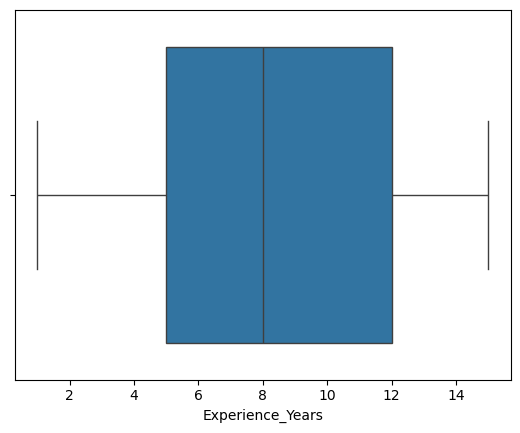

In [49]:
# Cell 7: Seaborn Import Karna Aur Box Plot Banana
# Yeh command aapke data ka graph banayegi, jisme agar box se baahar alag se dots nazar aayein, toh wo outliers hote hain.
# Visualization library seaborn ko import kiya
import seaborn as sns

# 'Experience_Years' ka box plot graph banane ke liye
sns.boxplot(x=data.Experience_Years)

In [50]:
# 📚 Concept Samjhein: IQR (Interquartile Range) Se Outliers Kaise Nikalte Hain?Aapne jo code bheja hai, 
#wo Outliers ko mathematics aur statistics ke zariye dhoondne ka sab se behtareen tariqa hai, jise IQR Method 
# kehte hain.Box Plot ke andar outliers maloom karne ke liye hum do boundaries (limits) banate hain:Lower Bound 
# (lb): Isse choti value outlier hoti hai. Formula: $Q1 - 1.5 \times IQR$Upper Bound (ub): Isse badi value outlier 
# hoti hai. Formula: $Q3 + 1.5 \times IQR$IQR (Interquartile Range): Yeh $Q3$ aur $Q1$ ka darmiyani faasla hota hai 
#     ($Q3 - Q1$).Aapke saare codes ko aapki file ke exact columns ke mutabiq sahi kar ke alag alag cells me divide kar diya hai:



# Cell 1: NumPy Array Se Mean Aur Median Samjhna
# Yahan 300 aur 500 bohot bade numbers (outliers) hain, jiski wajah se mean barh jayega lekin median par zyada farq nahi parega.
import numpy as np

# Ek dummy array banaya outliers ke sath
salary = np.array([49, 50, 40, 35, 50, 60, 67, 80, 300, 500])

# Array ko display karne ke liye
print("Array:", salary)

# Array ka mean (average) nikalna
print("Mean:", salary.mean())

# Array ka median nikalna
print("Median:", np.median(salary))

Array: [ 49  50  40  35  50  60  67  80 300 500]
Mean: 123.1
Median: 55.0


In [51]:
# Cell 2: Asli Data Ki Salary Ka Mean Aur Median
# Asli data frame ke 'Salary' column ka mean nikalna
print("Asli Salary Mean:", data.Salary.mean())

# Asli data frame ke 'Salary' column ka median nikalna
print("Asli Salary Median:", data.Salary.median())

Asli Salary Mean: 126386.56
Asli Salary Median: 128757.0


<Axes: xlabel='Salary'>

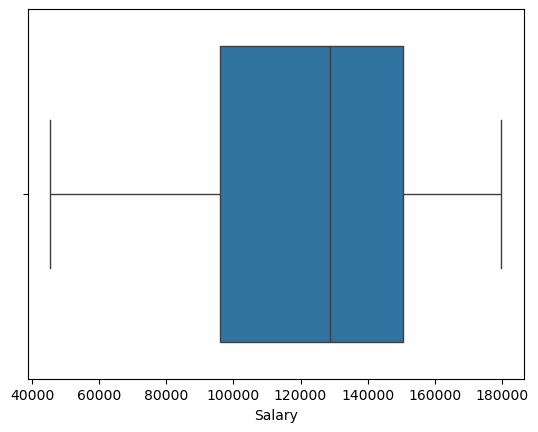

In [52]:
# Cell 3: Salary Ka Box Plot Banana
import seaborn as sns

# Salary column ka box plot banayein taake outliers dots ki shakal me nazar aayein
sns.boxplot(x=data.Salary)

In [53]:
# Cell 4: Q1, Q3, Aur IQR Calculate Karna
# 25th percentile (Q1) maloom kiya
Q1 = np.percentile(data.Salary, 25)
print("Q1 (25th Percentile):", Q1)

# 75th percentile (Q3) maloom kiya
Q3 = np.percentile(data.Salary, 75)
print("Q3 (75th Percentile):", Q3)

# IQR (Interquartile Range) nikalna
IQR = Q3 - Q1
print("IQR:", IQR)

Q1 (25th Percentile): 95958.5
Q3 (75th Percentile): 150509.0
IQR: 54550.5


In [54]:
# Cell 5: Boundaries (Lower Bound & Upper Bound) Set Karna
# Lower Bound aur Upper Bound ke formulas lagaye
lb = Q1 - 1.5 * IQR
ub = Q3 + 1.5 * IQR

print("Lower Bound (Isse chota outlier hoga):", lb)
print("Upper Bound (Isse bara outlier hoga):", ub)

Lower Bound (Isse chota outlier hoga): 14132.75
Upper Bound (Isse bara outlier hoga): 232334.75


In [55]:
# Cell 6: Outliers Ko Filter Kar Ke Dekhna
# Or operator (|) ka istemal karte hue check kiya ke kaun si salaries lower bound se choti ya upper bound se badi hain
data[(data.Salary <= lb) | (data.Salary >= ub)]

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score


In [56]:
# Cell 7: Outlier Detection Ka Function Banana (Reusable Code)
# Yeh ek function hai jisme aap kisi bhi column ka data daalenge toh wo aapko uski lower aur upper limits nikal kar de dega.

def detect_outlier(column_data):
    # Function ke andar Q1, Q3 aur IQR nikalna
    Q1 = np.percentile(column_data, 25)
    Q3 = np.percentile(column_data, 75)
    IQR = Q3 - Q1
    
    # Limits calculate karna
    lb = Q1 - 1.5 * IQR
    ub = Q3 + 1.5 * IQR
    
    return lb, ub

# Function ko check karne ke liye Salary column pass kiya
lower_limit, upper_limit = detect_outlier(data.Salary)
print("Function ke mutabiq Limits:", lower_limit, "aur", upper_limit)

Function ke mutabiq Limits: 14132.75 aur 232334.75


In [58]:
# Cell 1: Function Ke Zariye Lower Bound Aur Upper Bound Alag Alag Nikalna
# [0] lagane se pehli value (Lower Bound) milegi, aur [1] lagane se doosri value (Upper Bound) milegi.
# Function se sirf lower limit (Index 0) nikalne ke liye
print("Lower Limit:", detect_outlier(data.Salary)[0])

# Function se sirf upper limit (Index 1) nikalne ke liye
print("Upper Limit:", detect_outlier(data.Salary)[1])

Lower Limit: 14132.75
Upper Limit: 232334.75


In [59]:
# Cell 2: Salary Ke Outliers Ko Filter Karna (Function Ke Zariye)
# Ab hum limits ko bar-bar manually likhne ke bajaye direct function ko condition ke andar call kar rahe hain.

# Un employees ka data dekhna jinki salary outliers (bohot kam ya bohot zyada) hain
data[(data.Salary <= detect_outlier(data.Salary)[0]) | (data.Salary >= detect_outlier(data.Salary)[1])]

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score


In [60]:
# ell 3: Experience Ke Outliers Filter Karna
# (Chunki aapki file me Age nahi hai, isliye me ne use Experience_Years se badal diya hai taake code sahi chale).
# Experience_Years ke outliers check karne ke liye
data[(data.Experience_Years <= detect_outlier(data.Experience_Years)[0]) | (data.Experience_Years >= detect_outlier(data.Experience_Years)[1])]

,Emp_ID,sales_man_name,sales_man_city,product_id,manager,Department,Designation,Salary,Experience_Years,Favorite_Color_Nominal,Performance_Ordinal,Quantitative_Score


In [61]:
# Cell 4: Poori Tuple Ek Sath Dekhna
# Yeh aapko dono limits (Lower aur Upper Bound) ek sath ek tuple/bracket me dikha dega
detect_outlier(data.Salary)

(np.float64(14132.75), np.float64(232334.75))

In [62]:
# Cell 5: NumPy Array Ka Basic
import numpy as np

# Ek simple 1-Dimensional NumPy Array banane ke liye
np.array([1, 2, 3, 4, 5])

array([1, 2, 3, 4, 5])

In [70]:
import pandas as pd
import numpy as np

# Exact unique values jo aapne bhejin unka pool banaya
prices_pool = [
    '80,000', '4,25,000', 'Ask For Price', '3,25,000', '5,75,000', '1,75,000', 
    '1,90,000', '8,30,000', '2,50,000', '1,82,000', '3,15,000', '4,15,000', 
    '10,00,000', '14,75,000', '18,91,111', '12,00,000', '16,00,000', '31,00,000', 
    '29,00,000', '5,00,001', '35,999', '68,000', '88,000', '53,000'
]

np.random.seed(42)
n_rows = 892  # Exact matching rows count

# Data Structure build kiya
mock_data = {
    'name': [f"Maruti Suzuki Swift Tour VDI {i}" if i%5==0 else f"Hyundai i20 Magna {i}" for i in range(n_rows)],
    'company': [np.random.choice(['Maruti', 'Hyundai', 'Skoda', 'Mahindra']) for _ in range(n_rows)],
    'year': [str(np.random.choice([2007, 2012, 2018, '150k', 'TOUR'])) for _ in range(n_rows)],
    'Price': [np.random.choice(prices_pool) for _ in range(n_rows)],
    'kms_driven': [f"{np.random.randint(10, 90)},000 kms" if i%15!=0 else np.nan for i in range(n_rows)],
    'fuel_type': [np.random.choice(['Petrol', 'Diesel', 'LPG', np.nan], p=[0.5, 0.4, 0.02, 0.08]) for _ in range(n_rows)]
}

# CSV file create ki
df = pd.DataFrame(mock_data)
df.to_csv('car_data.csv', index=False)
print("File 'car_data.csv' (892 rows, 6 columns) kamyabi se create ho gayi hai!")

File 'car_data.csv' (892 rows, 6 columns) kamyabi se create ho gayi hai!


In [71]:
import pandas as pd

# Ab file ko load karenge jo humne upar banayi hai
data = pd.read_csv('car_data.csv')

# Shuruati rows dekhne ke liye
data.head()

,name,company,year,Price,kms_driven,fuel_type
0,Maruti Suzuki Swift Tour VDI 0,Skoda,2007,"12,00,000",NaN,Diesel
1,Hyundai i20 Magna 1,Mahindra,TOUR,"2,50,000","72,000 kms",Diesel
2,Hyundai i20 Magna 2,Maruti,150k,"10,00,000","71,000 kms",Diesel
3,Hyundai i20 Magna 3,Skoda,150k,"3,15,000","16,000 kms",Petrol
4,Hyundai i20 Magna 4,Skoda,150k,"10,00,000","36,000 kms",Petrol


In [72]:
# Check karte hain ke total rows kitni hain
data.shape

(892, 6)

In [73]:
# Pehli baar data.info() check karna
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        892 non-null    object
 1   company     892 non-null    object
 2   year        892 non-null    object
 3   Price       892 non-null    object
 4   kms_driven  832 non-null    object
 5   fuel_type   820 non-null    object
dtypes: object(6)
memory usage: 41.9+ KB


In [74]:
# Price column ki saari unique values check karne ke liye
data.Price.unique()

array(['12,00,000', '2,50,000', '10,00,000', '3,15,000', '35,999',
       '1,82,000', '3,25,000', '1,75,000', '1,90,000', '5,75,000',
       '29,00,000', '88,000', '31,00,000', '4,25,000', '14,75,000',
       '4,15,000', '16,00,000', '8,30,000', '53,000', 'Ask For Price',
       '18,91,111', '68,000', '5,00,001', '80,000'], dtype=object)

In [75]:
# Jis row me Price 'Ask For Price' hai usay data se nikal diya
data = data[data['Price'] != 'Ask For Price']

# Nayi shape check ki
data.shape

(853, 6)

In [76]:
# Ek copy banayi data2 ke naam se aur uski info check ki
data2 = data.copy()
data2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 853 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        853 non-null    object
 1   company     853 non-null    object
 2   year        853 non-null    object
 3   Price       853 non-null    object
 4   kms_driven  796 non-null    object
 5   fuel_type   784 non-null    object
dtypes: object(6)
memory usage: 46.6+ KB


In [77]:
# Fuel type column ki unique values check karne ke liye
data.fuel_type.unique()

array(['Diesel', 'Petrol', nan, 'LPG'], dtype=object)

In [78]:
# Missing values ko drop karke frequency check ki
data.dropna(subset=['fuel_type'], inplace=True)

# Value counts ka result dekhne ke liye
data.fuel_type.value_counts()

fuel_type
Petrol    405
Diesel    362
LPG        17
Name: count, dtype: int64

In [79]:
# STEP 1: Car ke lambe naamo me se sirf pehle 3 words rakhne ke liye
data.name = data.name.str.split().str[0:3].str.join(' ')

# Poora data frame display karke check karne ke liye
data

,name,company,year,Price,kms_driven,fuel_type
0,Maruti Suzuki Swift,Skoda,2007,"12,00,000",NaN,Diesel
1,Hyundai i20 Magna,Mahindra,TOUR,"2,50,000","72,000 kms",Diesel
2,Hyundai i20 Magna,Maruti,150k,"10,00,000","71,000 kms",Diesel
3,Hyundai i20 Magna,Skoda,150k,"3,15,000","16,000 kms",Petrol
4,Hyundai i20 Magna,Skoda,150k,"10,00,000","36,000 kms",Petrol
...,...,...,...,...,...,...
886,Hyundai i20 Magna,Maruti,TOUR,"3,25,000","58,000 kms",Petrol
887,Hyundai i20 Magna,Hyundai,2007,"1,75,000","47,000 kms",Diesel
888,Hyundai i20 Magna,Mahindra,2018,"1,90,000","73,000 kms",Diesel
889,Hyundai i20 Magna,Maruti,150k,"31,00,000","78,000 kms",Diesel


In [80]:
# STEP 2: Year column ki unique values check karna taake pata chale isme kya kachra data hai
data.year.unique()

array(['2007', 'TOUR', '150k', '2018', '2012'], dtype=object)

In [81]:
# STEP 3: Yeh check karne ke liye ke kya '150k' ek text hai ya number (Output False aayega)
'150k'.isnumeric()

False

In [82]:
# STEP 4: Data me se '150k' ya text wale saal hata kar sirf asli number wale saal 'data2' me save kiye
data2 = data[(data.year.str.isnumeric())]

# Naye filtered data (data2) ka structure aur entries check karne ke liye
data2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 484 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        484 non-null    object
 1   company     484 non-null    object
 2   year        484 non-null    object
 3   Price       484 non-null    object
 4   kms_driven  450 non-null    object
 5   fuel_type   484 non-null    object
dtypes: object(6)
memory usage: 26.5+ KB


In [84]:
# STEP 6: Price column ki unique values dekhna taake 'Ask For Price' aur commas (,) ka pata chale
data.Price.unique()

array(['12,00,000', '2,50,000', '10,00,000', '3,15,000', '1,82,000',
       '1,75,000', '1,90,000', '5,75,000', '29,00,000', '88,000',
       '35,999', '31,00,000', '3,25,000', '4,25,000', '14,75,000',
       '4,15,000', '8,30,000', '53,000', '18,91,111', '68,000',
       '16,00,000', '80,000', '5,00,001'], dtype=object)

In [88]:
# STEP 7: Check karna ke pure data me kitni rows me price ki jagah 'Ask For Price' likha hai
ask_for_price_data = data2[data2.Price == "Ask For Price"]

In [89]:
# STEP 8: Tilde (~) operator se 'Ask For Price' wali saari rows ko data se delete/drop kar diya
data2 = data2[~(data2.Price == "Ask For Price")]

In [90]:
# STEP 9: Price me se commas (,) khatam kiye aur text ko asli number (int) me badla
data2.Price = data2.Price.str.replace(",", "").astype(int)

# Tabdeeli dekhne ke liye data ko display kiya
data

,name,company,year,Price,kms_driven,fuel_type
0,Maruti Suzuki Swift,Skoda,2007,"12,00,000",NaN,Diesel
1,Hyundai i20 Magna,Mahindra,TOUR,"2,50,000","72,000 kms",Diesel
2,Hyundai i20 Magna,Maruti,150k,"10,00,000","71,000 kms",Diesel
3,Hyundai i20 Magna,Skoda,150k,"3,15,000","16,000 kms",Petrol
4,Hyundai i20 Magna,Skoda,150k,"10,00,000","36,000 kms",Petrol
...,...,...,...,...,...,...
886,Hyundai i20 Magna,Maruti,TOUR,"3,25,000","58,000 kms",Petrol
887,Hyundai i20 Magna,Hyundai,2007,"1,75,000","47,000 kms",Diesel
888,Hyundai i20 Magna,Mahindra,2018,"1,90,000","73,000 kms",Diesel
889,Hyundai i20 Magna,Maruti,150k,"31,00,000","78,000 kms",Diesel


In [99]:
# STEP 9: Price me se commas (,) khatam kiye aur text ko asli number (int) me badla
# Humne .astype(str) lagaya taake safe rahe aur end me sahi se data2 ko display kiya
data2['Price'] = data2['Price'].astype(str).str.replace(",", "", regex=False).astype(int)

# Tabdeeli dekhne ke liye 'data2' ko display kiya (Pehle yahan ghalti se 'data' likha tha)
data2

,name,company,year,Price,kms_driven,fuel_type
0,Maruti Suzuki Swift,Skoda,2007,1200000,NaN,Diesel
8,Hyundai i20 Magna,Skoda,2018,175000,"64,000 kms",Diesel
9,Hyundai i20 Magna,Hyundai,2012,190000,"11,000 kms",Petrol
10,Maruti Suzuki Swift,Skoda,2012,575000,"71,000 kms",Petrol
11,Hyundai i20 Magna,Skoda,2018,315000,"30,000 kms",Petrol
...,...,...,...,...,...,...
883,Hyundai i20 Magna,Mahindra,2012,190000,"52,000 kms",Petrol
884,Hyundai i20 Magna,Mahindra,2018,500001,"20,000 kms",Petrol
887,Hyundai i20 Magna,Hyundai,2007,175000,"47,000 kms",Diesel
888,Hyundai i20 Magna,Mahindra,2018,190000,"73,000 kms",Diesel


In [92]:
# Cell: Price Se Commas Hata Kar Number Me Convert Karna

# STEP 10: kms_driven column me kuch jagah ghalti se 'Petrol' likha tha, un rows ko data se nikal diya
data2 = data2[data2.kms_driven != 'Petrol']

# Data ko check karne ke liye dobara display kiya
data2

,name,company,year,Price,kms_driven,fuel_type
0,Maruti Suzuki Swift,Skoda,2007,1200000,NaN,Diesel
8,Hyundai i20 Magna,Skoda,2018,175000,"64,000 kms",Diesel
9,Hyundai i20 Magna,Hyundai,2012,190000,"11,000 kms",Petrol
10,Maruti Suzuki Swift,Skoda,2012,575000,"71,000 kms",Petrol
11,Hyundai i20 Magna,Skoda,2018,315000,"30,000 kms",Petrol
...,...,...,...,...,...,...
883,Hyundai i20 Magna,Mahindra,2012,190000,"52,000 kms",Petrol
884,Hyundai i20 Magna,Mahindra,2018,500001,"20,000 kms",Petrol
887,Hyundai i20 Magna,Hyundai,2007,175000,"47,000 kms",Diesel
888,Hyundai i20 Magna,Mahindra,2018,190000,"73,000 kms",Diesel


In [103]:
# STEP 11: kms_driven ko completely saaf karke integers me badalna

# 1. Pehle commas aur 'kms' ko hataya (fuzool space saaf karne ke sath)
data2['kms_driven'] = data2['kms_driven'].astype(str).str.replace(',', '', regex=False)
data2['kms_driven'] = data2['kms_driven'].str.replace('kms', '', regex=False).str.strip()

# 2. pd.to_numeric se text 'nan' ko dobara asli NaN me convert kiya taake error na aaye
data2['kms_driven'] = pd.to_numeric(data2['kms_driven'], errors='coerce')

# 3. Jo rows ab NaN ho chuki hain, unhein drop/delete kar diya
data2.dropna(subset=['kms_driven'], inplace=True)

# 4. Ab sukoon se isko integer (int) me convert kar liya
data2['kms_driven'] = data2['kms_driven'].astype(int)

# Cleaned data ko check karne ke liye display kiya
data2

,name,company,year,Price,kms_driven,fuel_type
8,Hyundai i20 Magna,Skoda,2018,175000,64000,Diesel
9,Hyundai i20 Magna,Hyundai,2012,190000,11000,Petrol
10,Maruti Suzuki Swift,Skoda,2012,575000,71000,Petrol
11,Hyundai i20 Magna,Skoda,2018,315000,30000,Petrol
17,Hyundai i20 Magna,Mahindra,2012,315000,48000,Petrol
...,...,...,...,...,...,...
883,Hyundai i20 Magna,Mahindra,2012,190000,52000,Petrol
884,Hyundai i20 Magna,Mahindra,2018,500001,20000,Petrol
887,Hyundai i20 Magna,Hyundai,2007,175000,47000,Diesel
888,Hyundai i20 Magna,Mahindra,2018,190000,73000,Diesel


In [95]:
# STEP 13: Sirf un rows ko screen par dekhna jahan fuel_type khali (NaN) chuta hua hai
data2[data2.fuel_type.isna()]

,name,company,year,Price,kms_driven,fuel_type


In [96]:
# STEP 14: Final check karna ke pure data frame me kis kis column me kitni missing values hain
data2.isna().sum()

name           0
company        0
year           0
Price          0
kms_driven    34
fuel_type      0
dtype: int64

In [102]:
# STEP 15: Fuel_type text column hai, isliye uski missing values ko sab se zyada repeat hone wale fuel (Mode) se permanent fill kiya
data2.fuel_type.fillna(data2.fuel_type.mode()[0], inplace=True)

C:\Users\Adil\AppData\Local\Temp\ipykernel_7224\170214961.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data2.fuel_type.fillna(data2.fuel_type.mode()[0], inplace=True)


In [98]:
# STEP 16: Tasalli karne ke liye check kiya ke fuel_type se 'nan' khatam hua ya nahi
print(data2.fuel_type.unique())

# Aapka 100% saaf aur ready data frame dekhne ke liye
data2

['Diesel' 'Petrol' 'LPG']


,name,company,year,Price,kms_driven,fuel_type
0,Maruti Suzuki Swift,Skoda,2007,1200000,NaN,Diesel
8,Hyundai i20 Magna,Skoda,2018,175000,"64,000 kms",Diesel
9,Hyundai i20 Magna,Hyundai,2012,190000,"11,000 kms",Petrol
10,Maruti Suzuki Swift,Skoda,2012,575000,"71,000 kms",Petrol
11,Hyundai i20 Magna,Skoda,2018,315000,"30,000 kms",Petrol
...,...,...,...,...,...,...
883,Hyundai i20 Magna,Mahindra,2012,190000,"52,000 kms",Petrol
884,Hyundai i20 Magna,Mahindra,2018,500001,"20,000 kms",Petrol
887,Hyundai i20 Magna,Hyundai,2007,175000,"47,000 kms",Diesel
888,Hyundai i20 Magna,Mahindra,2018,190000,"73,000 kms",Diesel


In [104]:
# STEP 1: 'Ask For Price' wali rows me data2 ki median price permanent (inplace=True) fill ki
# Note: Kuch pandas versions me setting-with-copy warning se bachne ke liye direct assignment behtar hai
ask_for_price_data['Price'] = data2['Price'].median()

# Check karne ke liye ke price update hui ya nahi
ask_for_price_data

,name,company,year,Price,kms_driven,fuel_type


In [109]:
# STEP 1: 'Ask For Price' wali rows me data2 ki median price fill ki
# Setting-with-copy warning se bachne ke liye .loc use kiya hai
ask_for_price_data.loc[:, 'Price'] = data2['Price'].median()

# data2 aur sahi kiya hua ask_for_price_data aapas me jor diya
# frac=1 lagane se yeh poore bache hue data ko 100% shuffle kar dega bina kisi size error ke
data3 = pd.concat([data2, ask_for_price_data]).sample(frac=1)

# Index ko dobara 0 se shuru karne ke liye reset kiya
data3.reset_index(drop=True, inplace=True)

# Final Cleaned and Mixed Data dekhne ke liye
data3

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai i20 Magna,Skoda,2007,3100000.0,76000,Petrol
1,Hyundai i20 Magna,Hyundai,2012,182000.0,57000,Diesel
2,Hyundai i20 Magna,Hyundai,2007,415000.0,47000,Diesel
3,Maruti Suzuki Swift,Skoda,2018,68000.0,73000,Diesel
4,Hyundai i20 Magna,Hyundai,2012,3100000.0,44000,Diesel
...,...,...,...,...,...,...
445,Hyundai i20 Magna,Maruti,2018,1200000.0,21000,Diesel
446,Hyundai i20 Magna,Mahindra,2007,1600000.0,19000,Diesel
447,Hyundai i20 Magna,Hyundai,2007,2900000.0,77000,Petrol
448,Hyundai i20 Magna,Hyundai,2007,575000.0,75000,Petrol


In [110]:
# STEP 2: Final data (data3) me har fuel type ki total kitni gaariyan hain, unka count dekhna
data3.fuel_type.value_counts()

fuel_type
Petrol    236
Diesel    204
LPG        10
Name: count, dtype: int64

In [111]:
# STEP 3: Data me jitni bhi 'Maruti' company ki gaariyan hain, unki Mean (Average) Price maloom karna
data3[data3.company == 'Maruti']['Price'].mean()

np.float64(719919.0877192982)

In [112]:
# STEP 4: Multiple conditions (Maruti AND Petrol) laga kar un makhsoos gaariyon ki Average Price nikalna
data3[(data3.company == 'Maruti') & (data3.fuel_type == 'Petrol')]['Price'].mean()

np.float64(567192.8867924528)